# Lab — Polynomial Regression and Logistic Regression

**Course:** Machine Learning — module *Training Models*
**Estimated time:** 2 hours
**Format:** work directly in this notebook; run every cell, complete the `TODO` cells, and write your
answers in the markdown cells marked *Your answer*.
**How to submit:** hand in this notebook **with all cells executed** (Kernel → Restart & Run All) and
your answers filled in.

The lab has two halves. In **Part 1** you will apply the polynomial-regression workflow from the
lecture to a **real dataset** (`sklearn`'s diabetes dataset), instead of the synthetic quadratic data
used in class. In **Part 2** you will work through **logistic regression** end to end: the sigmoid,
the cost function, decision boundaries on the Iris dataset, and multiclass classification with softmax.

> **Advice:** keep every plot you are asked to make; the questions refer to them.

## Part 0 — Setup

Run these two cells first. They load the two datasets we will use throughout the lab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

import warnings
warnings.filterwarnings("ignore")

# ----- dataset 1: diabetes (regression) -----
# 442 patients; 10 standardized features (age, sex, bmi, bp, 6 blood-serum measurements)
# target: a quantitative measure of disease progression one year after baseline
diabetes = load_diabetes(as_frame=True)
X_diab, y_diab = diabetes.data, diabetes.target.values
X_tr, X_te, y_tr, y_te = train_test_split(X_diab, y_diab, test_size=0.3, random_state=42)
print("diabetes:", X_tr.shape[0], "train /", X_te.shape[0], "test;",
      X_diab.shape[1], "features")
print("target range:", y_diab.min(), "to", y_diab.max())

# ----- dataset 2: iris (classification) -----
iris = load_iris(as_frame=True)
print("iris:", iris.data.shape, "classes:", list(iris.target_names))

diabetes: 309 train / 133 test; 10 features
target range: 25.0 to 346.0
iris: (150, 4) classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## Part 1 — Polynomial regression on real data

The lecture fitted polynomials to a synthetic quadratic. Here you will do the same on the diabetes
dataset: predicting disease progression (target) from the body/blood measurements (features).
Note that the features are **already standardized** (mean 0, standard deviation 1), so a slope means
"expected change in progression per one standard deviation increase of the feature".

### Exercise 1 — Warm-up: one feature, one line

Start with the single most informative feature, `bmi`. Fit a plain `LinearRegression` on the
training set, print train/test MSE and $R^2$, and plot the data with the fitted line.

Train MSE: 3899.45479231627
Test MSE: 3884.936720961032
Train R²: 0.3657651200418852
Test R²: 0.2803417492440603


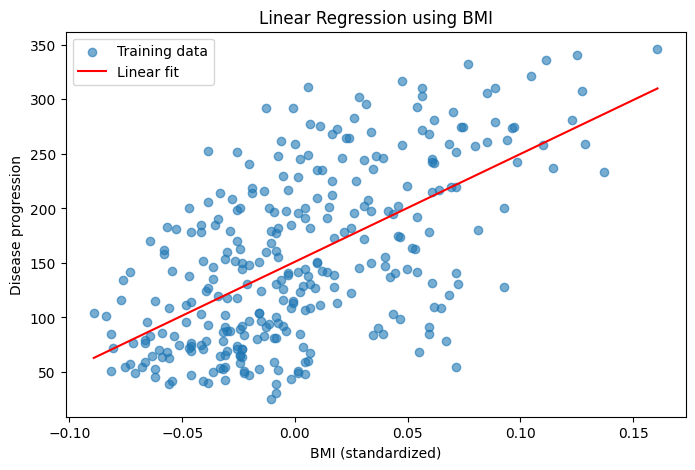

In [2]:
X_bmi_tr = X_tr[["bmi"]].values
X_bmi_te = X_te[["bmi"]].values

# Completed 1: fit a LinearRegression on X_bmi_tr, y_tr
lin_reg = LinearRegression()
lin_reg.fit(X_bmi_tr, y_tr)

# Completed 2: print train and test MSE and R^2
y_tr_pred = lin_reg.predict(X_bmi_tr)
y_te_pred = lin_reg.predict(X_bmi_te)
print("Train MSE:", mean_squared_error(y_tr, y_tr_pred))
print("Test MSE:", mean_squared_error(y_te, y_te_pred))
print("Train R²:", r2_score(y_tr, y_tr_pred))
print("Test R²:", r2_score(y_te, y_te_pred))

# Completed 3: plot the training data (scatter) and the fitted line on a grid of bmi values
grid = np.linspace(X_bmi_tr.min(), X_bmi_tr.max(), 300).reshape(-1, 1)
plt.figure(figsize=(8, 5))
plt.scatter(X_bmi_tr, y_tr, alpha=0.6, label="Training data")
plt.plot(grid, lin_reg.predict(grid), color="red", label="Linear fit")
plt.xlabel("BMI (standardized)")
plt.ylabel("Disease progression")
plt.title("Linear Regression using BMI")
plt.legend()
plt.show()

**My answer:** From the results, BMI has a positive relationship with disease progression, but it does not explain everything. The train MSE is about 3899 and the test MSE is about 3885, so the errors are quite similar. The R² scores are not very high, which means BMI alone is not enough to make very accurate predictions.

### Exercise 2 — More degrees, same line?

The lecture showed that `PolynomialFeatures` adds powers of a feature so that a *linear* model can fit
*nonlinear* data. Apply that to `bmi`: fit degrees 1, 2, 5 and 10, plot all four fitted curves on the
same scatter plot, and print the test MSE of each.

Degree 1 test MSE: 3884.936720961032
Degree 2 test MSE: 3905.281631795352
Degree 5 test MSE: 3877.8839963531505
Degree 10 test MSE: 4050.1039776148


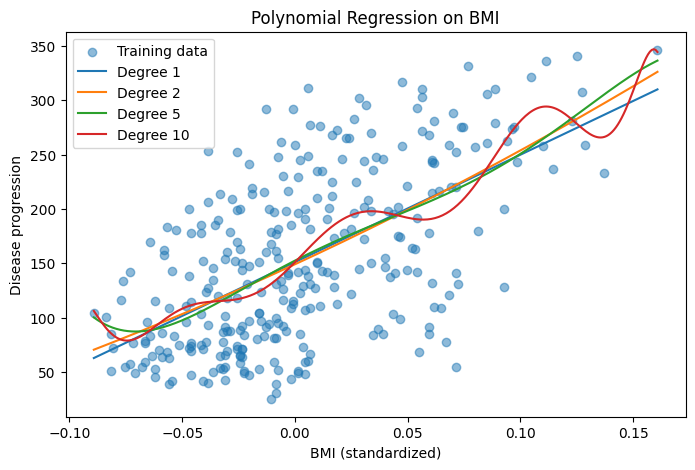

In [3]:
grid = np.linspace(X_bmi_tr.min(), X_bmi_tr.max(), 300).reshape(-1, 1)

# Completed 1: fit and plot polynomial models of degrees 1, 2, 5 and 10
# Completed 2: print the TEST MSE of each model
degrees = [1, 2, 5, 10]
plt.figure(figsize=(8, 5))
plt.scatter(X_bmi_tr, y_tr, alpha=0.5, label="Training data")

for deg in degrees:
    model = make_pipeline(PolynomialFeatures(deg), LinearRegression())
    model.fit(X_bmi_tr, y_tr)
    test_pred = model.predict(X_bmi_te)
    print(f"Degree {deg} test MSE:", mean_squared_error(y_te, test_pred))
    plt.plot(grid, model.predict(grid), label=f"Degree {deg}")

plt.xlabel("BMI (standardized)")
plt.ylabel("Disease progression")
plt.title("Polynomial Regression on BMI")
plt.legend()
plt.show()

**My answer:** When I increase the degree, the curve becomes more flexible. In my results, degree 5 has the lowest test MSE (about 3878), but it is only a little better than degree 1. Degree 10 has a higher test error, so making the model more complex does not always make it better.

### Exercise 3 — The same game with all 10 features

Now use **all ten features** at once. For degrees 1, 2 and 3: fit the polynomial regression on the
training set, print the number of features `PolynomialFeatures` produces, and report train and test
MSE. Then plot train and test MSE against the number of features.

Degree | Features | Train MSE | Test MSE
     1 |       11 |   2924.05 |  2821.75
     2 |       66 |   2409.43 |  3168.93
     3 |      286 |    462.80 | 501697.28


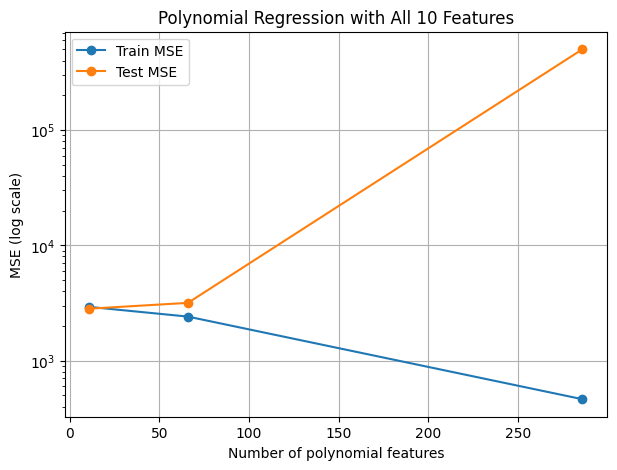

PolynomialFeatures(4) produces: 1001 features


In [4]:
results = []

# Completed 1: fit polynomial models for degrees 1, 2 and 3 and record metrics
for deg in [1, 2, 3]:
    model = make_pipeline(PolynomialFeatures(deg), LinearRegression())
    model.fit(X_tr.values, y_tr)
    n_features = model.named_steps["polynomialfeatures"].transform(X_tr.values).shape[1]
    train_pred = model.predict(X_tr.values)
    test_pred = model.predict(X_te.values)
    results.append((deg, n_features,
                    mean_squared_error(y_tr, train_pred),
                    mean_squared_error(y_te, test_pred)))

# Completed 2: print the three rows
print("Degree | Features | Train MSE | Test MSE")
for row in results:
    print(f"{row[0]:>6} | {row[1]:>8} | {row[2]:>9.2f} | {row[3]:>8.2f}")

# Completed 3: plot train and test MSE versus number of features
feature_counts = [r[1] for r in results]
train_mses = [r[2] for r in results]
test_mses = [r[3] for r in results]
plt.figure(figsize=(7, 5))
plt.plot(feature_counts, train_mses, marker="o", label="Train MSE")
plt.plot(feature_counts, test_mses, marker="o", label="Test MSE")
plt.yscale("log")
plt.xlabel("Number of polynomial features")
plt.ylabel("MSE (log scale)")
plt.title("Polynomial Regression with All 10 Features")
plt.legend()
plt.grid(True)
plt.show()

# Completed 4: count features for degree 4 (no regression model is fitted)
poly4 = PolynomialFeatures(4)
poly4.fit(X_tr.values)
print("PolynomialFeatures(4) produces:",
      poly4.transform(X_tr.values).shape[1], "features")

**My answer:** Degree 1 gives 11 features, degree 2 gives 66, and degree 3 gives 286. The training error gets smaller when the degree increases, but the test error gets much worse for degree 3. This is a clear sign of overfitting: the model fits the training data very well but does not work well on new data. Degree 4 would give 1001 features.

### Exercise 4 — What overfitting looks like in numbers (code modification)

The code below evaluates the degree-3 model on the test set. **Modify it**: instead of printing only
the MSE, print the **minimum, maximum and median of the predictions**, next to the same statistics of
the true test targets. Then answer the question.

In [5]:
m3 = make_pipeline(PolynomialFeatures(3), LinearRegression()).fit(X_tr.values, y_tr)
pred3 = m3.predict(X_te.values)

print("degree-3 test MSE:", mean_squared_error(y_te, pred3))

# Completed: compare prediction statistics with the true test-target statistics
print("\nPredictions (degree 3):")
print("Min:", np.min(pred3))
print("Max:", np.max(pred3))
print("Median:", np.median(pred3))

print("\nTrue test targets:")
print("Min:", np.min(y_te))
print("Max:", np.max(y_te))
print("Median:", np.median(y_te))

degree-3 test MSE: 501697.28074109874

Predictions (degree 3):
Min: -1917.651186950814
Max: 4853.218669896813
Median: 159.64110160249766

True test targets:
Min: 37.0
Max: 310.0
Median: 132.0


**My answer:** The degree-3 predictions go from about -1918 to 4853, while the real test values are only from 37 to 310. The median prediction is about 160 and the real median is 132. The very large and even negative predictions show that this model is unstable and is overfitting the data.

**Q1.** How many features would `PolynomialFeatures(4)` produce on the 10 diabetes variables?
Would you be able to fit it on the 309 training points? What would happen?

**My answer:** PolynomialFeatures(4) gives 1001 features. We only have 309 training examples, so there are many more features than examples. The model can fit the training data too closely, and the coefficients are not uniquely determined. I would not trust this model to predict new data without checking it carefully.

## Part 2 — Logistic regression

The second half of the lab follows the lecture: the sigmoid, the cost function, decision boundaries
on the Iris dataset, and softmax regression for three classes.

### Exercise 5 — The sigmoid function

Implement $\sigma(t) = \frac{1}{1+\exp(-t)}$ yourself (no sklearn), plot it for $t \in [-10, 10]$,
and check $\sigma(0)$, $\sigma(100)$, $\sigma(-100)$.

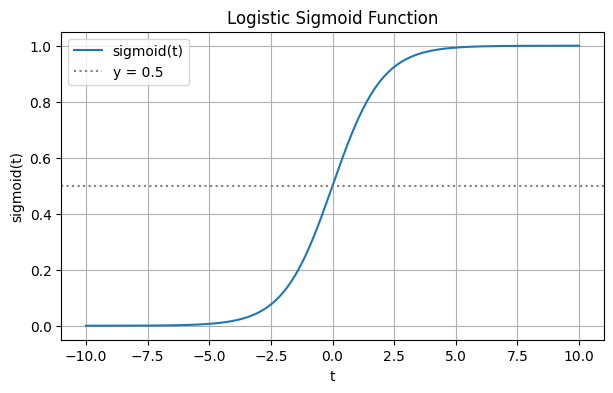

sigmoid(0): 0.5
sigmoid(100): 1.0
sigmoid(-100): 3.7200759760208356e-44


In [6]:
def sigmoid(t):
    # Logistic sigmoid: maps real-valued scores to probabilities in (0, 1)
    return 1 / (1 + np.exp(-np.asarray(t)))

# Plot the sigmoid and the 0.5 reference threshold
t = np.linspace(-10, 10, 400)
plt.figure(figsize=(7, 4))
plt.plot(t, sigmoid(t), label="sigmoid(t)")
plt.axhline(0.5, color="gray", linestyle=":", label="y = 0.5")
plt.xlabel("t")
plt.ylabel("sigmoid(t)")
plt.title("Logistic Sigmoid Function")
plt.legend()
plt.grid(True)
plt.show()

print("sigmoid(0):", sigmoid(0))
print("sigmoid(100):", sigmoid(100))
print("sigmoid(-100):", sigmoid(-100))

**My answer:** The sigmoid changes a number into a value between 0 and 1, which we can read as a probability. At 0 the result is 0.5. For a very positive number it gets close to 1, and for a very negative number it gets close to 0.

### Exercise 6 — The cost function

A logistic model is trained by giving high estimated probability to positive instances and low
probability to negative ones. The per-instance cost is

$$c(\theta) = \begin{cases} -\log \hat p & \text{if } y = 1 \\ -\log(1-\hat p) & \text{if } y = 0 \end{cases}$$

Implement it (vectorized: $-[y \log \hat p + (1-y)\log(1-\hat p)]$), plot both branches against
$\hat p$, and evaluate the cost of a *confidently wrong* prediction.

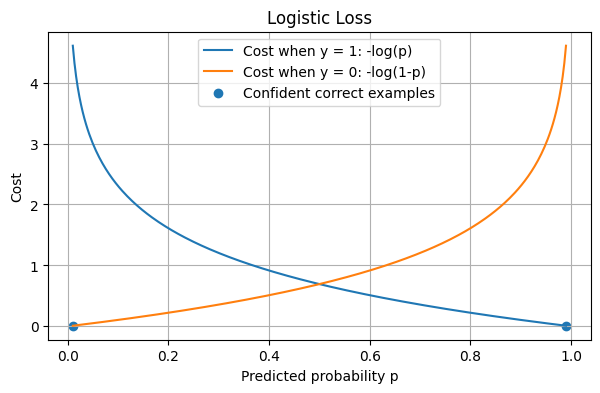

Correct and confident (y=1, p=0.99): 0.01005033585350145
Wrong and confident (y=1, p=0.01): 4.605170185988091


In [7]:
def log_loss(p, y):
    # Clip probabilities to avoid log(0); supports scalar or array inputs
    p = np.clip(np.asarray(p, dtype=float), 1e-15, 1 - 1e-15)
    y = np.asarray(y)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

# Completed 1: plot both branches of the logistic cost
p_values = np.linspace(0.01, 0.99, 300)
plt.figure(figsize=(7, 4))
plt.plot(p_values, -np.log(p_values), label="Cost when y = 1: -log(p)")
plt.plot(p_values, -np.log(1 - p_values), label="Cost when y = 0: -log(1-p)")
plt.scatter([0.99, 0.01], [-np.log(0.99), -np.log(0.99)],
            marker="o", label="Confident correct examples")
plt.xlabel("Predicted probability p")
plt.ylabel("Cost")
plt.title("Logistic Loss")
plt.legend()
plt.grid(True)
plt.show()

# Completed 2: compare confident correct and confidently wrong predictions
print("Correct and confident (y=1, p=0.99):", log_loss(0.99, 1))
print("Wrong and confident (y=1, p=0.01):", log_loss(0.01, 1))

**My answer:** When the model is correct and confident (p = 0.99), the loss is very small, around 0.01. When it is confidently wrong (p = 0.01), the loss is much bigger, around 4.61. So the cost function gives a strong penalty when the model is very confident but makes the wrong prediction.

### Exercise 7 — Decision boundary on one feature (reproduce the lecture)

Now reproduce the lecture's example: classify **Iris virginica** (class 2) against the other two
species using **petal width** alone. Fit a `LogisticRegression` on all 150 flowers, plot the data
points (0/1) together with the estimated probability curve, and compute where the decision boundary
falls: the boundary is where $\hat p = 0.5$, i.e. where $\theta_0 + \theta_1 x = 0$.

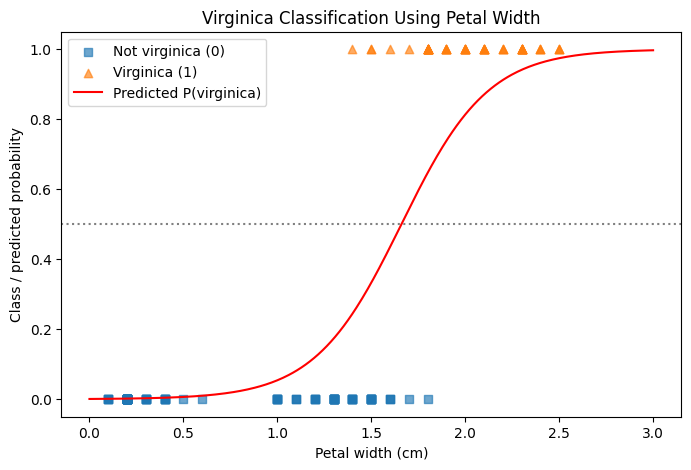

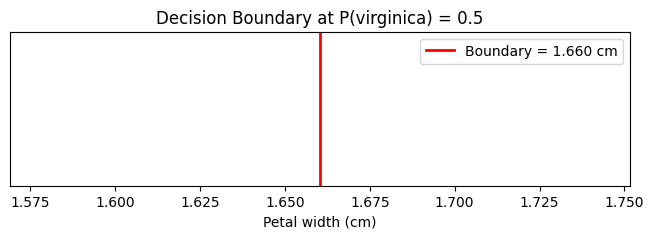

Coefficient: [4.33251974]
Intercept: -7.1934210576514905
Decision boundary (cm): 1.6603319735278124
Accuracy: 0.96


In [8]:
X_pw = iris.data[["petal width (cm)"]].values
y_virg = (iris.target == 2).astype(int)

# Starter model: used again in Exercise 8.
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_pw, y_virg)

# Completed 2: plot the two classes and predicted probability curve
width_grid = np.linspace(0, 3, 400).reshape(-1, 1)
prob_grid = log_reg.predict_proba(width_grid)[:, 1]

plt.figure(figsize=(8, 5))
plt.scatter(X_pw[y_virg == 0], y_virg[y_virg == 0],
            marker="s", alpha=0.65, label="Not virginica (0)")
plt.scatter(X_pw[y_virg == 1], y_virg[y_virg == 1],
            marker="^", alpha=0.65, label="Virginica (1)")
plt.plot(width_grid, prob_grid, color="red", label="Predicted P(virginica)")
plt.axhline(0.5, color="gray", linestyle=":")
plt.xlabel("Petal width (cm)")
plt.ylabel("Class / predicted probability")
plt.title("Virginica Classification Using Petal Width")
plt.legend()
plt.show()

# Completed 3: compute and draw the 0.5 decision boundary
slope = log_reg.coef_[0, 0]
intercept = log_reg.intercept_[0]
boundary = -intercept / slope
plt.figure(figsize=(8, 2))
plt.axvline(boundary, color="red", linewidth=2, label=f"Boundary = {boundary:.3f} cm")
plt.yticks([])
plt.xlabel("Petal width (cm)")
plt.title("Decision Boundary at P(virginica) = 0.5")
plt.legend()
plt.show()

# Completed 4: print coefficients, boundary and accuracy
pred_pw = log_reg.predict(X_pw)
print("Coefficient:", log_reg.coef_[0])
print("Intercept:", log_reg.intercept_[0])
print("Decision boundary (cm):", boundary)
print("Accuracy:", accuracy_score(y_virg, pred_pw))

**My answer:** The probability of virginica goes up when petal width gets bigger. In my model, the decision boundary is around 1.66 cm, so above this value the flower is predicted as virginica. The accuracy is 0.96, which means the model classified 96% of the flowers correctly.

### Exercise 8 — Change the threshold (code modification)

The 0.5 threshold is a convention, not a law. The code below computes the standard predictions.
**Modify it**: predict virginica when $\hat p$ exceeds **0.1** and **0.9** as well, and for each
threshold count how many **non-virginica flowers are wrongly labelled virginica** (false positives)
and how many **virginica flowers are missed** (false negatives).

In [9]:
proba = log_reg.predict_proba(X_pw)[:, 1]

pred = (proba >= 0.5).astype(int)
print("accuracy at 0.5:", accuracy_score(y_virg, pred))

# Completed: compare accuracy, false positives and false negatives at each threshold
for thr in [0.1, 0.5, 0.9]:
    threshold_pred = (proba >= thr).astype(int)
    false_positives = np.sum((threshold_pred == 1) & (y_virg == 0))
    false_negatives = np.sum((threshold_pred == 0) & (y_virg == 1))
    print(f"Threshold {thr:.1f}: accuracy={accuracy_score(y_virg, threshold_pred):.3f}, "
          f"false positives={false_positives}, false negatives={false_negatives}")

accuracy at 0.5: 0.96
Threshold 0.1: accuracy=0.733, false positives=40, false negatives=0
Threshold 0.5: accuracy=0.960, false positives=2, false negatives=4
Threshold 0.9: accuracy=0.780, false positives=0, false negatives=33


**My answer:** With threshold 0.1, the model predicts virginica more often. It has 40 false positives and no false negatives, so it catches all virginica flowers but also labels many other flowers incorrectly. With threshold 0.9, there are no false positives but 33 false negatives. At 0.5, the accuracy is best in my results (0.96), with 2 false positives and 4 false negatives.

### Exercise 9 — Decision boundary with two features

Now use **petal length and petal width** together (still virginica vs rest). Fit the model on the
whole dataset, draw a contour plot of the estimated probability over the two-feature plane (with
contour lines at 0.15, 0.45, 0.75, 0.9 like the lecture), mark the 0.5 boundary, and add the data
points. Then evaluate honestly: split train/test and report the test accuracy.

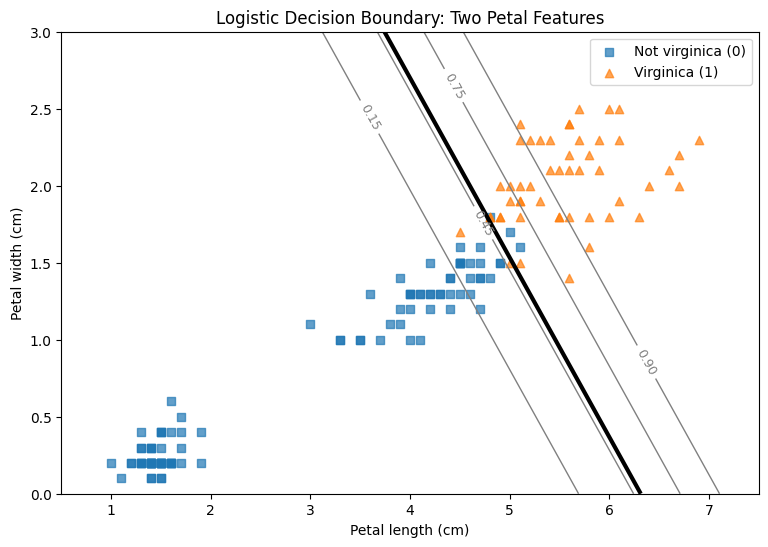

Train accuracy: 0.9553571428571429
Test accuracy: 1.0


In [10]:
X_pl = iris.data[["petal length (cm)", "petal width (cm)"]].values

# Completed 1: fit logistic regression using both petal measurements
log2d = LogisticRegression(random_state=42)
log2d.fit(X_pl, y_virg)

# Completed 2: calculate probabilities on a mesh grid
lengths = np.linspace(0.5, 7.5, 300)
widths = np.linspace(0, 3, 250)
g1, g2 = np.meshgrid(lengths, widths)
grid_points = np.column_stack([g1.ravel(), g2.ravel()])
prob_grid = log2d.predict_proba(grid_points)[:, 1].reshape(g1.shape)

# Completed 3: draw probability contours and the two classes
plt.figure(figsize=(9, 6))
contours = plt.contour(g1, g2, prob_grid,
                       levels=[0.15, 0.45, 0.75, 0.9],
                       colors="gray", linewidths=1)
plt.clabel(contours, inline=True, fontsize=9)
plt.contour(g1, g2, prob_grid, levels=[0.5],
            colors="black", linewidths=3)
plt.scatter(X_pl[y_virg == 0, 0], X_pl[y_virg == 0, 1],
            marker="s", alpha=0.7, label="Not virginica (0)")
plt.scatter(X_pl[y_virg == 1, 0], X_pl[y_virg == 1, 1],
            marker="^", alpha=0.7, label="Virginica (1)")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Logistic Decision Boundary: Two Petal Features")
plt.legend()
plt.show()

# Completed 4: evaluate a train/test split
X_pl_tr, X_pl_te, y_virg_tr, y_virg_te = train_test_split(
    X_pl, y_virg, test_size=0.25, random_state=42
)
log2d_split = LogisticRegression(random_state=42)
log2d_split.fit(X_pl_tr, y_virg_tr)
print("Train accuracy:", accuracy_score(y_virg_tr, log2d_split.predict(X_pl_tr)))
print("Test accuracy:", accuracy_score(y_virg_te, log2d_split.predict(X_pl_te)))

**My answer:** Using both petal length and petal width gives the model more information than using only petal width. The 0.5 contour is the decision boundary between virginica and the other flowers. The training accuracy is about 95.5% and the test accuracy is 100% in this split, so the model performs very well on this test set.

### Exercise 10 — Softmax regression: three classes at once (open-ended)

Finally, reproduce the multiclass example from the lecture: a single model that assigns probabilities
to **all three** species at once (softmax regression). With the two petal features:

1. Fit `LogisticRegression(C=30, random_state=42)` on all three classes and predict the class and
   probabilities for a flower with petal length 5 cm and petal width 2 cm.
2. **Verify by hand**: the model stores one parameter vector per class (`coef_`, `intercept_`).
   Compute the scores $s_k = \theta_0^{(k)} + \theta^{(k)\top} x$ yourself, then apply the softmax
   formula $\hat p_k = \exp s_k / \sum_j \exp s_j$ and check you get the same probabilities as
   `predict_proba`.
3. Plot the three decision regions with the data points (colored background via `contourf`).

*Note:* `LogisticRegression` applies an L2 penalty by default; `C` controls it (larger = trust the data
more). We have not covered regularization yet — for now just keep `C=30` as in the lecture slides.

Predicted class: 2 - virginica
Predicted probabilities: [2.08408710e-08 2.85939761e-02 9.71406003e-01]
Scores (manual): [-10.59637656   3.53541406   7.0609625 ]
Probabilities (manual softmax): [2.08408710e-08 2.85939761e-02 9.71406003e-01]
Matches predict_proba: True


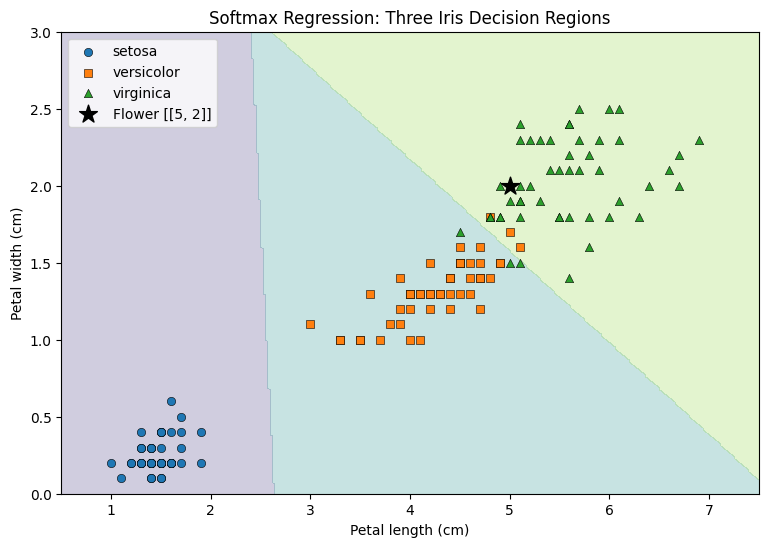

In [11]:
# Completed 1: fit softmax regression and predict for the flower [[5, 2]]
softmax_reg = LogisticRegression(C=30, random_state=42)
softmax_reg.fit(X_pl, iris.target)
flower = np.array([[5, 2]])
predicted_class = softmax_reg.predict(flower)[0]
predicted_probabilities = softmax_reg.predict_proba(flower)[0]
print("Predicted class:", predicted_class, "-", iris.target_names[predicted_class])
print("Predicted probabilities:", predicted_probabilities)

# Completed 2: calculate scores and probabilities by hand
scores = softmax_reg.intercept_ + softmax_reg.coef_ @ flower.ravel()
exp_scores = np.exp(scores - np.max(scores))  # stable softmax
manual_probabilities = exp_scores / exp_scores.sum()
print("Scores (manual):", scores)
print("Probabilities (manual softmax):", manual_probabilities)
print("Matches predict_proba:", np.allclose(manual_probabilities, predicted_probabilities))

# Completed 3: plot the three decision regions and observations
lengths = np.linspace(0.5, 7.5, 300)
widths = np.linspace(0, 3, 250)
g1, g2 = np.meshgrid(lengths, widths)
grid_points = np.column_stack([g1.ravel(), g2.ravel()])
region_predictions = softmax_reg.predict(grid_points).reshape(g1.shape)

plt.figure(figsize=(9, 6))
plt.contourf(g1, g2, region_predictions, alpha=0.25, levels=[-0.5, 0.5, 1.5, 2.5])
for class_id, marker in zip([0, 1, 2], ["o", "s", "^"]):
    mask = iris.target == class_id
    plt.scatter(X_pl[mask, 0], X_pl[mask, 1], marker=marker,
                label=iris.target_names[class_id], edgecolor="black", linewidth=0.4)
plt.scatter(flower[0, 0], flower[0, 1], marker="*", s=180,
            color="black", label="Flower [[5, 2]]")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Softmax Regression: Three Iris Decision Regions")
plt.legend()
plt.show()

**My answer:** Softmax regression gives probabilities for all three Iris classes, and the probabilities add up to 1. For the flower [5, 2], the model predicts virginica with a probability of about 97.1%. I also calculated the scores and probabilities manually, and they match the model's predict_proba result.

## Part 3 — Open questions

Answer in your own words; 3–5 sentences each.

**Q1.** Logistic regression is a *classification* algorithm. Why is it called *regression*?

**My answer:** It is called regression because the model first calculates a numerical score from the input features. This score is the log-odds, and then the sigmoid changes it into a probability between 0 and 1. We use that probability to decide which class the example belongs to, so the final use is classification.

**Q2.** Why not simply fit a linear regression to the 0/1 labels and threshold its predictions at 0.5?

**My answer:** Linear regression can give predictions smaller than 0 or bigger than 1, which does not make sense as probabilities. It is also not designed for classifying data with only two possible labels. Logistic regression is better because it keeps the output between 0 and 1 and models the probability of each class.

**Q3.** Your colleague fits the degree-3 diabetes model from Exercise 3, sees training MSE 585 against 2900 for the linear model, and proposes to deploy it in the clinic. Write the two sentences you would tell them.

**My answer:** I would not deploy the model just because its training MSE is lower. A low training error can mean that the model has memorized the training data, especially with degree 3. We should check the test error or use cross-validation and test it on new patients first. Since this is for a clinic, it also needs careful validation before being used.

**Q4.** A flower with petal width 1.7 cm gets $\hat p(\text{virginica}) \approx 0.6$. The botanist asks: "so is it a virginica or not?" How do you answer, and how is that better than just saying yes or no?

**My answer:** I would tell the botanist that the model gives a 60% probability that the flower is virginica. If we use the usual 0.5 threshold, it will be classified as virginica, but the model is not completely sure. Giving the probability is more useful than only saying yes or no because it shows the uncertainty.

**Q5.** Softmax: if you add 100 to *all* the scores $s_k$ of an instance, what happens to the probabilities $\hat p_k$? And what happens if you multiply all scores by 100?

**My answer:** If we add 100 to every score, the probabilities stay the same because the extra factor cancels out in the softmax formula. But if we multiply all the scores by 100, the probabilities usually change. The differences between the scores become much bigger, so the model becomes more confident in the class with the highest score.